In [10]:
import pandas as pd

df = pd.read_csv("C:/Users/RGUKT/Downloads/archive/imdb_top_1000.csv")

print(df.shape)
print(df.columns)

(1000, 16)
Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='str')


In [11]:
# Check the first 5 movie records
df.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [12]:
# Check dataset size
print("Rows and columns:", df.shape)

# Check data types and missing values
df.info()

Rows and columns: (1000, 16)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   str    
 1   Series_Title   1000 non-null   str    
 2   Released_Year  1000 non-null   str    
 3   Certificate    899 non-null    str    
 4   Runtime        1000 non-null   str    
 5   Genre          1000 non-null   str    
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   str    
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   str    
 10  Star1          1000 non-null   str    
 11  Star2          1000 non-null   str    
 12  Star3          1000 non-null   str    
 13  Star4          1000 non-null   str    
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    str    
dtypes: float64(2), int64(1), str(13)
memory usage: 520.0 KB


In [13]:
# Count missing values in each column
df.isnull().sum()

Poster_Link        0
Series_Title       0
Released_Year      0
Certificate      101
Runtime            0
Genre              0
IMDB_Rating        0
Overview           0
Meta_score       157
Director           0
Star1              0
Star2              0
Star3              0
Star4              0
No_of_Votes        0
Gross            169
dtype: int64

In [14]:
# Select useful columns for prediction
df = df[[
    "Series_Title",
    "Released_Year",
    "Runtime",
    "Genre",
    "Director",
    "Star1",
    "Star2",
    "Star3",
    "Star4",
    "No_of_Votes",
    "IMDB_Rating"
]]

# Check missing values again
print(df.isnull().sum())

Series_Title     0
Released_Year    0
Runtime          0
Genre            0
Director         0
Star1            0
Star2            0
Star3            0
Star4            0
No_of_Votes      0
IMDB_Rating      0
dtype: int64


In [15]:
# Convert release year into numbers
df["Released_Year"] = pd.to_numeric(
    df["Released_Year"], errors="coerce"
)

# Extract numbers from Runtime and convert to numeric
df["Runtime"] = pd.to_numeric(
    df["Runtime"].str.replace(" min", "", regex=False),
    errors="coerce"
)

# Check the result
print(df[["Series_Title", "Released_Year", "Runtime"]].head())

print("\nMissing values:")
print(df[["Released_Year", "Runtime"]].isnull().sum())

               Series_Title  Released_Year  Runtime
0  The Shawshank Redemption         1994.0      142
1             The Godfather         1972.0      175
2           The Dark Knight         2008.0      152
3    The Godfather: Part II         1974.0      202
4              12 Angry Men         1957.0       96

Missing values:
Released_Year    1
Runtime          0
dtype: int64


In [16]:
df.shape

(1000, 11)

In [17]:
df = df.dropna(
    subset=["Released_Year", "Runtime", "Genre", "Director"]
)

df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (999, 11)


In [19]:
genre_rating=df.groupby("Genre")["IMDB_Rating"].mean()
print(genre_rating.sort_values(ascending=False))

Genre
Animation, Drama, War         8.50
Action, Sci-Fi                8.40
Drama, Musical                8.40
Drama, Mystery, War           8.35
Western                       8.35
                              ... 
Action, Adventure, Mystery    7.60
Action, Adventure, Family     7.60
Action, Adventure, Crime      7.60
Animation, Drama, Romance     7.60
Drama, War, Western           7.60
Name: IMDB_Rating, Length: 202, dtype: float64


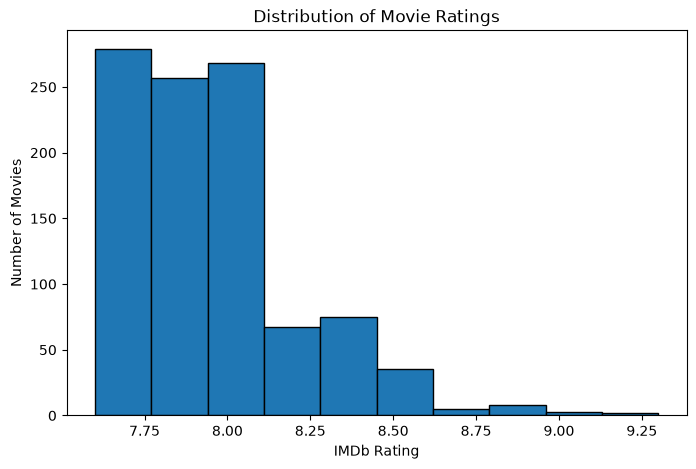

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["IMDB_Rating"], bins=10, edgecolor="black")

plt.title("Distribution of Movie Ratings")
plt.xlabel("IMDb Rating")
plt.ylabel("Number of Movies")

plt.show()

In [21]:
# Select input features and target
features = [
    "Released_Year",
    "Runtime",
    "Genre",
    "Director",
    "Star1",
    "Star2",
    "Star3",
    "Star4",
    "No_of_Votes"
]

X = df[features]
y = df["IMDB_Rating"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (999, 9)
Target shape: (999,)


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = [
    "Released_Year",
    "Runtime",
    "No_of_Votes"
]

categorical_features = [
    "Genre",
    "Director",
    "Star1",
    "Star2",
    "Star3",
    "Star4"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

print("Feature preprocessing is ready!")

Feature preprocessing is ready!


In [23]:
X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)

Original shape: (999, 9)
Processed shape: (999, 4082)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)
print("Training ratings:", y_train.shape)
print("Testing ratings:", y_test.shape)

Training input: (799, 9)
Testing input: (200, 9)
Training ratings: (799,)
Testing ratings: (200,)


In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [26]:
# Predict ratings for test movies
y_pred = model.predict(X_test)

# Display actual and predicted ratings
results = pd.DataFrame({
    "Actual Rating": y_test,
    "Predicted Rating": y_pred
})

print(results.head(10).round(2))

     Actual Rating  Predicted Rating
453            8.0              7.90
793            7.7              7.76
209            8.1              8.00
309            8.1              8.24
740            7.7              7.74
578            7.8              7.75
895            7.6              8.03
545            7.9              7.85
436            8.0              7.95
678            7.8              7.74


In [27]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

RMSE: 0.217
R2 Score: 0.282


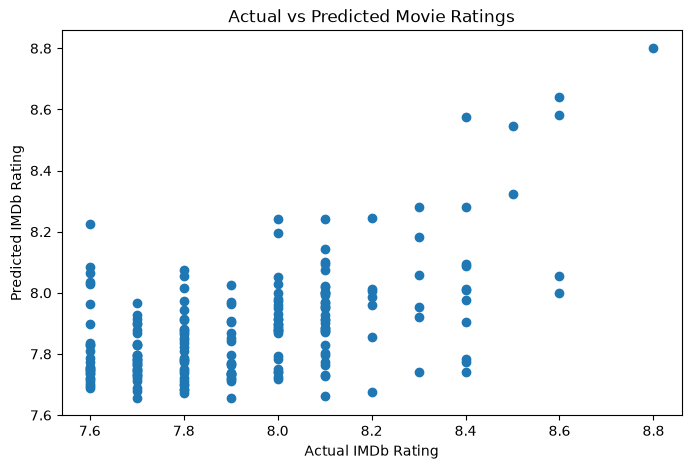

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual IMDb Rating")
plt.ylabel("Predicted IMDb Rating")
plt.title("Actual vs Predicted Movie Ratings")

plt.show()

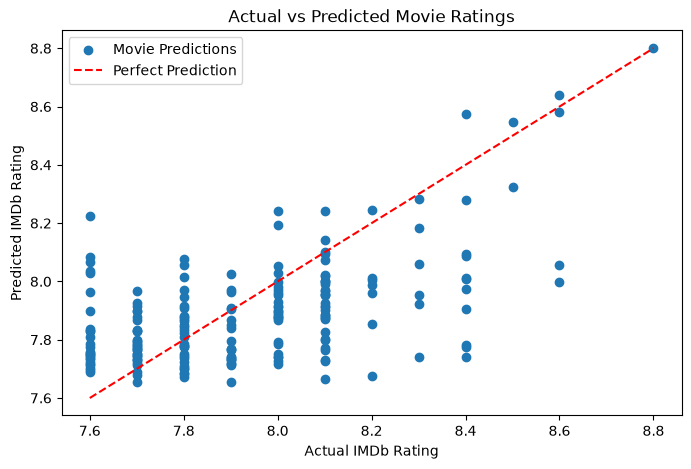

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, label="Movie Predictions")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual IMDb Rating")
plt.ylabel("Predicted IMDb Rating")
plt.title("Actual vs Predicted Movie Ratings")
plt.legend()
plt.show()

In [31]:
#new movie prediction
new_movie = pd.DataFrame([{
    "Released_Year": 2020,
    "Runtime": 120,
    "Genre": "Drama",
    "Director": "Christopher Nolan",
    "Star1": "Actor A",
    "Star2": "Actor B",
    "Star3": "Actor C",
    "Star4": "Actor D",
    "No_of_Votes": 100000
}])

predicted_rating = model.predict(new_movie)

print("Predicted IMDb Rating:", round(predicted_rating[0], 2))

Predicted IMDb Rating: 7.86


In [32]:
movie = df.iloc[[0]]

print(movie[[
    "Series_Title",
    "Released_Year",
    "Runtime",
    "Genre",
    "IMDB_Rating"
]])

               Series_Title  Released_Year  Runtime  Genre  IMDB_Rating
0  The Shawshank Redemption         1994.0      142  Drama          9.3


In [33]:
movie_input = movie[features]

predicted_rating = model.predict(movie_input)

print("Movie Name:", movie["Series_Title"].iloc[0])
print("Actual Rating:", movie["IMDB_Rating"].iloc[0])
print("Predicted Rating:", round(predicted_rating[0], 2))

Movie Name: The Shawshank Redemption
Actual Rating: 9.3
Predicted Rating: 9.13


In [34]:
import joblib

joblib.dump(model, "movie_rating_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [35]:
import os
print(os.getcwd())

C:\Users\RGUKT


In [36]:
import ipywidgets as widgets

print("Dashboard library ready!")

Dashboard library ready!


In [41]:

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import pandas as pd

# Dashboard title
header = widgets.HTML("""
<div style="background:linear-gradient(120deg,#172554,#4338ca);
            padding:25px;border-radius:15px;color:white;
            text-align:center;">
    <h1 style="margin:0;">🎬 Movie Rating Predictor</h1>
    <p style="margin:10px 0 0;">
        Discover an estimated IMDb rating using Machine Learning
    </p>
</div>
""")

# Input style
style = {"description_width": "110px"}
layout = widgets.Layout(width="100%", height="38px")

year = widgets.IntText(
    value=2020, description="Release Year:",
    style=style, layout=layout
)
runtime = widgets.IntText(
    value=120, description="Runtime (min):",
    style=style, layout=layout
)
genre = widgets.Text(
    value="Drama", description="Genre:",
    style=style, layout=layout
)
director = widgets.Text(
    value="", placeholder="Enter director name",
    description="Director:", style=style, layout=layout
)
star1 = widgets.Text(
    value="", placeholder="Enter actor name",
    description="Star 1:", style=style, layout=layout
)
star2 = widgets.Text(
    value="", placeholder="Enter actor name",
    description="Star 2:", style=style, layout=layout
)
star3 = widgets.Text(
    value="", placeholder="Enter actor name",
    description="Star 3:", style=style, layout=layout
)
star4 = widgets.Text(
    value="", placeholder="Enter actor name",
    description="Star 4:", style=style, layout=layout
)
votes = widgets.IntText(
    value=100000, description="IMDb Votes:",
    style=style, layout=layout
)

section1 = widgets.HTML("""
<h3 style="color:#4338ca;border-bottom:2px solid #c7d2fe;
padding-bottom:8px;">🎞️ Movie Information</h3>
""")

section2 = widgets.HTML("""
<h3 style="color:#4338ca;border-bottom:2px solid #c7d2fe;
padding-bottom:8px;">🎭 Cast & Popularity</h3>
""")

movie_grid = widgets.GridBox(
    [year, runtime, genre, director],
    layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(0, 1fr))",
        grid_gap="12px"
    )
)

cast_grid = widgets.GridBox(
    [star1, star2, star3, star4, votes],
    layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(0, 1fr))",
        grid_gap="12px"
    )
)

predict_button = widgets.Button(
    description="⭐ Predict Movie Rating",
    button_style="primary",
    icon="star",
    layout=widgets.Layout(width="100%", height="45px")
)

result = widgets.Output()

def predict_rating(b):
    with result:
        clear_output(wait=True)

        new_movie = pd.DataFrame([{
            "Released_Year": year.value,
            "Runtime": runtime.value,
            "Genre": genre.value.strip(),
            "Director": director.value.strip(),
            "Star1": star1.value.strip(),
            "Star2": star2.value.strip(),
            "Star3": star3.value.strip(),
            "Star4": star4.value.strip(),
            "No_of_Votes": votes.value
        }])[features]

        if (
            year.value < 1888 or year.value > 2100
            or runtime.value <= 0 or votes.value < 0
            or not genre.value.strip()
            or not director.value.strip()
            or not all([
                star1.value.strip(), star2.value.strip(),
                star3.value.strip(), star4.value.strip()
            ])
        ):
            display(HTML("""
            <div style="background:#fee2e2;padding:15px;
            border-radius:10px;color:#991b1b;">
            Please enter valid movie details in every field.
            </div>
            """))
            return

        prediction = model.predict(new_movie)[0]

        display(HTML(f"""
        <div style="background:#eef2ff;border:1px solid #a5b4fc;
                    padding:22px;border-radius:14px;text-align:center;">
            <h3 style="color:#3730a3;margin-top:0;">
                🎉 Predicted IMDb Rating
            </h3>
            <div style="font-size:38px;font-weight:bold;color:#4338ca;">
                ⭐ {prediction:.2f} / 10
            </div>
            <p style="color:#374151;">
                This is a machine-learning estimate, not an official rating.
            </p>
        </div>
        """))

predict_button.on_click(predict_rating)
footer = widgets.HTML("""
<p style="text-align:center;color:#64748b;font-size:12px;">
Discover your movie rating prediction above.
</p>
""")


dashboard = widgets.VBox(
    [
        header,
        section1,
        movie_grid,
        section2,
        cast_grid,
        predict_button,
        result,
        footer
    ],
    layout=widgets.Layout(
        width="100%",
        max_width="900px",
        padding="18px",
        border="1px solid #e2e8f0"
    )
)

display(dashboard)


In [44]:
import os

for file in os.listdir():
    if file.endswith((".ipynb", ".pkl", ".csv")):
        print(file)

cleaned_student_dataset.csv
cleane_student_dataset.csv
movie prediction.ipynb
movie_rating_model.pkl
Titanic Survival prediction.ipynb
Untitled.ipynb
Untitled1.ipynb
Untitled2.ipynb
Untitled3.ipynb
Untitled4.ipynb
Untitled5.ipynb
Untitled6.ipynb
used_cars.csv
